In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#config
k = 10                  # number of arms
steps = 1000            # time steps
runs = 2000             # independent runs
c_ucb = 2               # UCB parameter
    
np.random.seed(42)

In [3]:
#bandit environment
class Bandit:
    def __init__(self, k=10):
        self.k = k
        self.q_true = np.random.normal(0, 1, k)  # True action values

    def pull(self, action):
        return np.random.normal(self.q_true[action], 1)


In [4]:
#action selection methods

def epsilon_greedy(Q, epsilon):
    if np.random.rand() < epsilon:
        return np.random.randint(len(Q))
    return np.argmax(Q)

def ucb(Q, counts, t, c=2):
    ucb_values = Q + c * np.sqrt(np.log(t + 1) / (counts + 1e-5))
    return np.argmax(ucb_values)


In [5]:
#simulation function

def run_experiment(method):
    avg_rewards = np.zeros(steps)

    for run in range(runs):
        bandit = Bandit(k)
        Q = np.zeros(k)
        counts = np.zeros(k)
        rewards = np.zeros(steps)

        # Optimistic initialization
        if method == "optimistic":
            Q = np.ones(k) * 5

        for t in range(steps):

            if method == "greedy":
                action = epsilon_greedy(Q, 0)

            elif method == "eps_0.01":
                action = epsilon_greedy(Q, 0.01)

            elif method == "eps_0.1":
                action = epsilon_greedy(Q, 0.1)

            elif method == "optimistic":
                action = np.argmax(Q)

            elif method == "ucb":
                action = ucb(Q, counts, t+1, c=c_ucb)

            reward = bandit.pull(action)

            counts[action] += 1
            Q[action] += (reward - Q[action]) / counts[action]

            rewards[t] = reward

        avg_rewards += rewards

    return avg_rewards / runs



In [6]:
#running all methods
methods = [
    "greedy",
    "eps_0.01",
    "eps_0.1",
    "optimistic",
    "ucb"
]

results = {}

for m in methods:
    print(f"Running {m}...")
    results[m] = run_experiment(m)

Running greedy...
Running eps_0.01...
Running eps_0.1...
Running optimistic...
Running ucb...


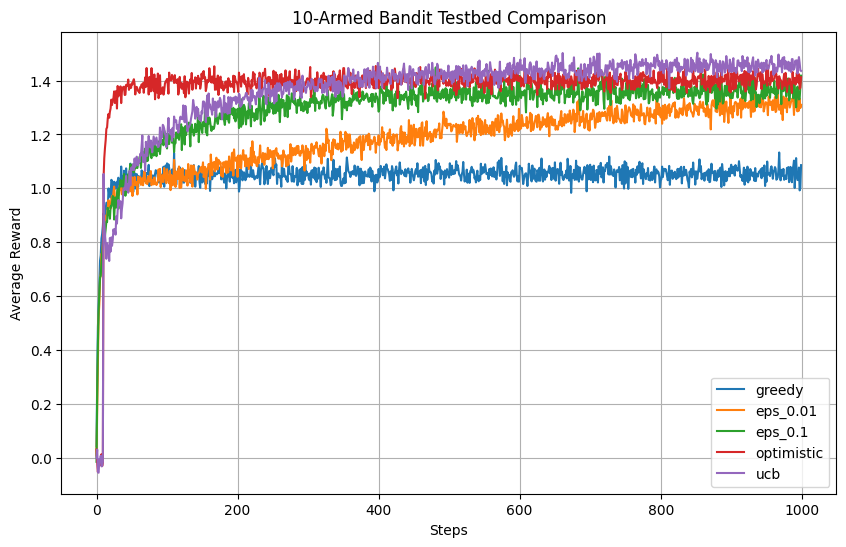

In [7]:
#plot results 
plt.figure(figsize=(10,6))

for m in methods:
    plt.plot(results[m], label=m)

plt.xlabel("Steps")
plt.ylabel("Average Reward")
plt.title("10-Armed Bandit Testbed Comparison")
plt.legend()
plt.grid()
plt.show()